In [5]:
# ignore this
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

# Global Spectrum of Plant Form and Function

## References

- Diaz et al., 2016, Global Spectrum of Plant Form and Function
- Weigelt et al. 2021, An integrated framework of plant form and function: the belowground perspective
- Wolf et al. 2022, Citizen science plant observations encode global trait patterns

## Exercise Outline

1. Correlate sPlotOpen data with trait grid cell averages

2. Calculate PCA with top traits from correlation analysis (come up with a good cut-off)
    - Plot variance explained
    - Plot biplots with loadings
    - Create global maps for the PCs that explain most variance
    - Try to interpret PCs in ecological terms
    - Describe what regions are not well covered and discuss how this may influence the PCA


3. Choose a biome and quantify and visualitze trait shifts from native -> all (**group**)

4. Quantify and visualize trait shifts in a specific biome



## Data

- Grid-cell averages: ```/net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_imp.csv```
    - **h3_res3**: h3 hexagonal equal-area grid cells at reolution 3
    - **group**: only indigenous observations (native) and indigenous+non-indigenous observations
    - **count**: number of occurences per grid cell (sampling density)
    - - **37 above- and below-ground plant functional traits** (citizen-science species occurrence merged with TRY trait data), gap-filled

- sPlotOpen: ```~/iNaturalist/Data/sPlotOpen/cwm_loc.csv```
    - **PlotID**
    - **Latitude**
    - **Longitude**
    - **Community weighted means (CWM's)** for 18 above-ground traits
    - a bunch of other variables

- Trait names: ```~/Func_Neo_Phytes/Data/trait_info.csv```

- WWF biomes shapefile: ```~/iNaturalist/Data/WWF/wwf_terr_ecos.shp```

## Corrlate with sPlotOpen

1. Calculate grid-cell sPlotOpen averages

In [43]:
# read ~/iNaturalist/Data/sPlotOpen/cwm_loc.csv
splotopen <- read.csv("~/iNaturalist/Data/sPlotOpen/cwm_loc.csv")
head(splotopen)

,PlotObservationID,TraitCoverage_cover,Species_richness,TraitCoverage_pa,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,⋯,Height_shrubs_lowest,Height_herbs_average,Height_herbs_lowest,Height_herbs_highest,SoilClim_PC1,SoilClim_PC2,Resample_1,Resample_2,Resample_3,Resample_1_consensus
,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,16,0.27777778,3,0.3333333,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
2,17,0.03846154,2,0.5000000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
3,18,0.04761905,4,0.2500000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,False,False,True,False
4,20,0.66666667,3,0.3333333,3.686063,-0.9071351,2.903715,6.136791,2.929729,0.7391809,⋯,NA,NA,NA,NA,-3.66,0.546,False,True,False,False
5,22,0.53846154,7,0.5714286,3.899842,-0.9005136,2.917708,6.131968,2.955072,0.7336978,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
6,23,0.95238095,13,0.8461538,4.225747,-0.8226879,2.638385,6.158266,2.843045,0.2463386,⋯,NA,NA,NA,NA,-3.66,0.546,False,False,True,False


In [44]:
# column names splotopen    
names(splotopen)


[1] "PlotObservationID"      "TraitCoverage_cover"    "Species_richness"      
 [4] "TraitCoverage_pa"       "Leaf.Area"              "SSD"                   
 [7] "SLA"                    "Leaf.C"                 "Leaf.N.per.mass"       
[10] "Leaf.P"                 "Plant.Height"           "Seed.mass"             
[13] "Seed.length"            "LDMC"                   "Leaf.N.per.area"       
[16] "Leaf.N.P.ratio"         "Leaf.delta15N"          "Seeds.per.rep..unit"   
[19] "Leaf.fresh.mass"        "Stem.conduit.density"   "Dispersal.unit.length" 
[22] "Conduit.element.length" "LeafArea_CWV"           "StemDens_CWV"          
[25] "SLA_CWV"                "LeafC_perdrymass_CWV"   "LeafN_CWV"             
[28] "LeafP_CWV"              "PlantHeight_CWV"        "SeedMass_CWV"          
[31] "Seed_length_CWV"        "LDMC_CWV"               "LeafNperArea_CWV"      
[34] "LeafNPratio_CWV"        "Leaf_delta_15N_CWV"     "Seed_num_rep_unit_CWV" 
[37] "Leaffreshmass_CWV"      "Stem_cond_dens_CWV"     "Disp_unit_leng_CWV"    
[40] "Wood_vessel_length_CWV" "GIVD_ID"                "Dataset"               
[43] "Continent"              "Country"                "Biome"                 
[46] "Date_of_recording"      "Latitude"               "Longitude"             
[49] "Location_uncertainty"   "Releve_area"            "Plant_recorded"        
[52] "Elevation"              "Aspect"                 "Slope"                 
[55] "is_forest"              "ESY"                    "Naturalness"           
[58] "Forest"                 "Shrubland"              "Grassland"             
[61] "Wetland"                "Sparse_vegetation"      "Cover_total"           
[64] "Cover_tree_layer"       "Cover_shrub_layer"      "Cover_herb_layer"      
[67] "Cover_moss_layer"       "Cover_lichen_layer"     "Cover_algae_layer"     
[70] "Cover_litter_layer"     "Cover_bare_rocks"       "Cover_cryptogams"      
[73] "Cover_bare_soil"        "Height_trees_highest"   "Height_trees_lowest"   
[76] "Height_shrubs_highest"  "Height_shrubs_lowest"   "Height_herbs_average"  
[79] "Height_herbs_lowest"    "Height_herbs_highest"   "SoilClim_PC1"          
[82] "SoilClim_PC2"           "Resample_1"             "Resample_2"            
[85] "Resample_3"             "Resample_1_consensus"

In [45]:
# add h3 hexagonal grid cell code at resolution 3

library(h3) 

splotopen$h3_res3 <- geo_to_h3(cbind(splotopen$Latitude, splotopen$Longitude), res = 3)
head(splotopen)

,PlotObservationID,TraitCoverage_cover,Species_richness,TraitCoverage_pa,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,⋯,Height_herbs_average,Height_herbs_lowest,Height_herbs_highest,SoilClim_PC1,SoilClim_PC2,Resample_1,Resample_2,Resample_3,Resample_1_consensus,h3_res3
,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
1,16,0.27777778,3,0.3333333,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,-3.66,0.546,True,False,False,True,830c0dfffffffff
2,17,0.03846154,2,0.5000000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,-3.66,0.546,True,False,False,True,830c0dfffffffff
3,18,0.04761905,4,0.2500000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,-3.66,0.546,False,False,True,False,830c0dfffffffff
4,20,0.66666667,3,0.3333333,3.686063,-0.9071351,2.903715,6.136791,2.929729,0.7391809,⋯,NA,NA,NA,-3.66,0.546,False,True,False,False,830c0dfffffffff
5,22,0.53846154,7,0.5714286,3.899842,-0.9005136,2.917708,6.131968,2.955072,0.7336978,⋯,NA,NA,NA,-3.66,0.546,True,False,False,True,830c0dfffffffff
6,23,0.95238095,13,0.8461538,4.225747,-0.8226879,2.638385,6.158266,2.843045,0.2463386,⋯,NA,NA,NA,-3.66,0.546,False,False,True,False,830c0dfffffffff


In [46]:
# grid cell averages ...
library(data.table)
fdf <- as.data.table(splotopen) 
fdf <- fdf[, lapply(.SD, mean, na.rm = TRUE), by = .(h3_res3), .SDcols = 5:22]
head(fdf)
dim(fdf)

h3_res3,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,Plant.Height,Seed.mass,Seed.length,LDMC,Leaf.N.per.area,Leaf.N.P.ratio,Leaf.delta15N,Seeds.per.rep..unit,Leaf.fresh.mass,Stem.conduit.density,Dispersal.unit.length,Conduit.element.length
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
830c0dfffffffff,5.286020,-0.6767926,2.547086,6.175948,2.862541,0.4098426,-1.39150810,-1.16317760,0.6846575,-1.0542035,0.4223804,2.470260,0.63209872,5.335786,-2.783946,5.485476,0.7850149,6.240016
830d0dfffffffff,5.198045,-0.7471362,2.274660,6.164345,2.785955,0.3008645,-1.81075782,-0.84815693,0.7265356,-0.9310762,0.6015856,2.432048,0.70711660,4.710749,-2.724683,5.546541,0.7271709,6.240027
830d09fffffffff,5.425017,-0.8202089,2.430393,6.175138,2.878956,0.3947741,-1.06276613,-1.07742213,0.6837733,-1.0281507,0.5362389,2.451325,0.41047794,5.227728,-2.686133,5.571741,0.8647338,6.112316
830d1dfffffffff,5.673696,-0.9112180,2.405599,6.154917,2.860321,0.4054245,-1.03344633,-1.15282416,0.6101166,-1.0286873,0.5366637,2.413937,0.54469992,5.707986,-2.412464,5.617495,0.8157300,6.313104
830d0cfffffffff,5.076076,-0.6920378,2.411308,6.172855,2.816234,0.3726307,-1.49165972,-1.19423362,0.6092392,-0.9692410,0.4870674,2.393390,0.65518950,5.497273,-2.923317,5.330322,0.6881776,6.165346
830c34fffffffff,6.224304,-0.7900717,2.399637,6.146253,2.882490,0.4622680,0.06446531,-0.07326834,0.9682199,-1.1758056,0.5209463,2.368610,0.02107625,5.248281,-1.824061,4.755991,1.2820929,5.946835


[1] 2021   19

2. Correlation sPlotOpen and community science-based grid cell averages for all traits


In [47]:
traits <- read.csv("~/Func_Neo_Phytes/Data/trait_info.csv")
traits

TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
<int>,<chr>,<chr>,<chr>,<chr>,<chr>
4,X.X4.,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
6,X.X6.,Root rooting depth,Rooting depth,,m
13,X.X13.,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
14,X.X14.,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
15,X.X15.,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
21,X.X21.,Stem diameter,Stem diameter,,m
26,X.X26.,Seed dry mass,Seed dry mass,Seed.mass,mg
27,X.X27.,Seed length,Seed length,Seed.length,mm
46,X.X46.,Leaf thickness,Leaf thickness,,mm


In [48]:
# load datatable package
library(data.table)

# read /net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_imp.csv
gbif <- fread("/net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_imp.csv")
head(gbif)

h3_res3,group,count,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,⋯,X.X223.,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,534527,18.214,22.920,1.517,23.667,4.787,4.419,10.888,⋯,27.280,4.836,4681.834,1.231,0.601,89.707,1334.172,3946.738,-0.386,0.442
832830fffffffff,native,378645,16.342,21.572,1.552,25.367,4.365,4.558,10.751,⋯,27.200,5.368,4343.244,1.292,0.665,88.577,957.992,3313.235,-0.861,0.471
832834fffffffff,all,449715,17.946,22.496,1.543,24.300,4.618,3.993,11.110,⋯,27.261,4.910,4562.517,1.228,0.633,89.730,1493.841,3848.960,-0.478,0.453
832834fffffffff,native,334995,15.877,21.214,1.582,25.657,4.229,4.024,11.045,⋯,27.287,5.420,4273.462,1.282,0.739,88.691,953.885,3216.443,-0.897,0.478
832831fffffffff,all,64487,18.615,21.891,1.429,24.619,4.800,4.665,11.035,⋯,27.500,5.051,4777.817,1.224,0.630,89.313,1341.667,3642.961,-0.634,0.442
832831fffffffff,native,51697,17.566,20.829,1.440,26.203,4.583,4.882,10.949,⋯,27.537,5.512,4525.613,1.261,0.678,88.553,900.762,3129.122,-1.049,0.460


In [49]:
# make dictionary (long → short)
trait_dict <- setNames(traits$sPlotOpenName, traits$TraitID_TRY6)

# rename
setnames(gbif,
         old = intersect(names(gbif), names(trait_dict)),
         new = trait_dict[intersect(names(gbif), names(trait_dict))])

head(gbif)

h3_res3,group,count,SLA,Leaf.N.per.mass,Leaf.N.per.area,,.1,.2,.3,⋯,,Dispersal.unit.length,.1,.2,.3,.4,Seeds.per.rep..unit,.5,Leaf.delta15N,SSD
<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,all,534527,18.214,22.920,1.517,23.667,4.787,4.419,10.888,⋯,27.280,4.836,4681.834,1.231,0.601,89.707,1334.172,3946.738,-0.386,0.442
832830fffffffff,native,378645,16.342,21.572,1.552,25.367,4.365,4.558,10.751,⋯,27.200,5.368,4343.244,1.292,0.665,88.577,957.992,3313.235,-0.861,0.471
832834fffffffff,all,449715,17.946,22.496,1.543,24.300,4.618,3.993,11.110,⋯,27.261,4.910,4562.517,1.228,0.633,89.730,1493.841,3848.960,-0.478,0.453
832834fffffffff,native,334995,15.877,21.214,1.582,25.657,4.229,4.024,11.045,⋯,27.287,5.420,4273.462,1.282,0.739,88.691,953.885,3216.443,-0.897,0.478
832831fffffffff,all,64487,18.615,21.891,1.429,24.619,4.800,4.665,11.035,⋯,27.500,5.051,4777.817,1.224,0.630,89.313,1341.667,3642.961,-0.634,0.442
832831fffffffff,native,51697,17.566,20.829,1.440,26.203,4.583,4.882,10.949,⋯,27.537,5.512,4525.613,1.261,0.678,88.553,900.762,3129.122,-1.049,0.460


In [50]:
intersect(names(fdf), names(gbif))


[1] "h3_res3"                "Leaf.Area"              "SSD"                   
 [4] "SLA"                    "Leaf.C"                 "Leaf.N.per.mass"       
 [7] "Leaf.P"                 "Plant.Height"           "Seed.mass"             
[10] "Seed.length"            "LDMC"                   "Leaf.N.per.area"       
[13] "Leaf.delta15N"          "Seeds.per.rep..unit"    "Leaf.fresh.mass"       
[16] "Stem.conduit.density"   "Dispersal.unit.length"  "Conduit.element.length"

In [51]:
# Find shared trait columns (excluding the grid)
shared_traits <- intersect(names(fdf), names(gbif))
shared_traits <- setdiff(shared_traits, "h3_res3")  # remove grid ID

# Keep only the grid + shared traits
fdf_sub  <- fdf[, .SD, .SDcols = c("h3_res3", shared_traits)]
gbif_sub <- gbif[, .SD, .SDcols = c("h3_res3", shared_traits)]



In [52]:
head(fdf_sub)

h3_res3,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,Plant.Height,Seed.mass,Seed.length,LDMC,Leaf.N.per.area,Leaf.delta15N,Seeds.per.rep..unit,Leaf.fresh.mass,Stem.conduit.density,Dispersal.unit.length,Conduit.element.length
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
830c0dfffffffff,5.286020,-0.6767926,2.547086,6.175948,2.862541,0.4098426,-1.39150810,-1.16317760,0.6846575,-1.0542035,0.4223804,0.63209872,5.335786,-2.783946,5.485476,0.7850149,6.240016
830d0dfffffffff,5.198045,-0.7471362,2.274660,6.164345,2.785955,0.3008645,-1.81075782,-0.84815693,0.7265356,-0.9310762,0.6015856,0.70711660,4.710749,-2.724683,5.546541,0.7271709,6.240027
830d09fffffffff,5.425017,-0.8202089,2.430393,6.175138,2.878956,0.3947741,-1.06276613,-1.07742213,0.6837733,-1.0281507,0.5362389,0.41047794,5.227728,-2.686133,5.571741,0.8647338,6.112316
830d1dfffffffff,5.673696,-0.9112180,2.405599,6.154917,2.860321,0.4054245,-1.03344633,-1.15282416,0.6101166,-1.0286873,0.5366637,0.54469992,5.707986,-2.412464,5.617495,0.8157300,6.313104
830d0cfffffffff,5.076076,-0.6920378,2.411308,6.172855,2.816234,0.3726307,-1.49165972,-1.19423362,0.6092392,-0.9692410,0.4870674,0.65518950,5.497273,-2.923317,5.330322,0.6881776,6.165346
830c34fffffffff,6.224304,-0.7900717,2.399637,6.146253,2.882490,0.4622680,0.06446531,-0.07326834,0.9682199,-1.1758056,0.5209463,0.02107625,5.248281,-1.824061,4.755991,1.2820929,5.946835


In [53]:
# put fdf_sub in expotential space , becuase the data was log-transformed before
fdf_sub[, (shared_traits) := lapply(.SD, function(x) exp(x)), .SDcols = shared_traits]

In [54]:
head(fdf_sub)

h3_res3,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,Plant.Height,Seed.mass,Seed.length,LDMC,Leaf.N.per.area,Leaf.delta15N,Seeds.per.rep..unit,Leaf.fresh.mass,Stem.conduit.density,Dispersal.unit.length,Conduit.element.length
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
830c0dfffffffff,197.5555,0.5082445,12.76983,481.0390,17.50595,1.506581,0.2487000,0.3124916,1.983092,0.3484699,1.525589,1.881555,207.6359,0.06179418,241.1637,2.192440,512.8665
830d0dfffffffff,180.9182,0.4737212,9.72461,475.4896,16.21530,1.351026,0.1635302,0.4282034,2.067904,0.3941293,1.825010,2.028135,111.1354,0.06556700,256.3494,2.069218,512.8726
830d09fffffffff,227.0153,0.4403397,11.36335,480.6495,17.79569,1.484049,0.3454988,0.3404721,1.981340,0.3576678,1.709565,1.507538,186.3688,0.06814395,262.8915,2.374374,451.3828
830d1dfffffffff,291.1084,0.4020342,11.08507,471.0277,17.46713,1.499939,0.3557787,0.3157438,1.840646,0.3574759,1.710291,1.724091,301.2637,0.08959428,275.1991,2.260825,551.7547
830d0cfffffffff,160.1444,0.5005550,11.14853,479.5531,16.71380,1.451548,0.2249989,0.3029360,1.839032,0.3793709,1.627536,1.925507,244.0255,0.05375507,206.5045,1.990085,475.9657
830c34fffffffff,504.8713,0.4538122,11.01918,466.9646,17.85869,1.587671,1.0665886,0.9293514,2.633253,0.3085703,1.683620,1.021300,190.2389,0.16136905,116.2789,3.604175,382.5406


In [55]:
#### Plot 
# Required libraries
library(ggplot2)
library(reshape2)

# Trait names
trait_names <- c('Dispersal unit len.', 'Leaf Area', 'SLA', 'Leaf C', 'LDMC',
                 'Leaf fresh mass', 'Leaf N per area', 'Leaf N per mass',
                 'Leaf delta15N', 'Leaf N P ratio', 'Leaf P', 'Plant Height',
                 'Seed mass', 'Seed length', 'Seeds per rep. unit',
                 'Stem conduit \ndensity', 'SSD', 'Conduit element len.')

# Data preparation
data_dropnan <- r_all[, colSums(is.na(r_all)) < nrow(r_all)]  # Drop columns with all NA
data_melt <- melt(data_dropnan, id.vars = "Resolution", variable.name = "variable", value.name = "r")

# Convert Resolution to factor for proper plotting
data_melt$Resolution <- as.factor(data_melt$Resolution)

# Plotting
ggplot(data_melt, aes(x = Resolution, y = r, group = variable, color = variable)) +
  geom_line(size = 0.6) +
  geom_point(size = 2) +
  theme_minimal(base_size = 14) +
  theme(legend.position = "none",
        axis.text.x = element_text(angle = 45, hjust = 1),
        plot.margin = margin(10, 10, 10, 10)) +
  labs(x = "Resolution in degrees", y = "r") +
  scale_x_discrete(limits = rev(levels(data_melt$Resolution))) +  # Reverse x-axis
  geom_text(data = data_melt[data_melt$Resolution == levels(data_melt$Resolution)[1], ],
            aes(label = variable), hjust = -0.1, size = 3, show.legend = FALSE)


ERROR: Error: object 'r_all' not found


In [56]:
# corrleate all traits in fdf_sub vs gbif_sub
library(dplyr)
library(tidyr)
library(purrr)  
library(ggplot2)
library(ggcorrplot)
library(data.table)
# merge by h3_res3
merged <- merge(fdf_sub, gbif_sub, by = "h3_res3", suffixes = c("_sPlotOpen", "_GBIF"))
head(merged)    

h3_res3,Leaf.Area_sPlotOpen,SSD_sPlotOpen,SLA_sPlotOpen,Leaf.C_sPlotOpen,Leaf.N.per.mass_sPlotOpen,Leaf.P_sPlotOpen,Plant.Height_sPlotOpen,Seed.mass_sPlotOpen,Seed.length_sPlotOpen,⋯,Seed.mass_GBIF,Seed.length_GBIF,LDMC_GBIF,Leaf.N.per.area_GBIF,Leaf.delta15N_GBIF,Seeds.per.rep..unit_GBIF,Leaf.fresh.mass_GBIF,Stem.conduit.density_GBIF,Dispersal.unit.length_GBIF,Conduit.element.length_GBIF
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
830029fffffffff,146.0484,0.3964689,16.76525,455.2239,15.99620,2.121103,0.2655275,0.2345321,1.236486,⋯,0.136,1.206,0.099,1.481,-0.782,234.222,0.034,227.810,1.163,597.788
830029fffffffff,146.0484,0.3964689,16.76525,455.2239,15.99620,2.121103,0.2655275,0.2345321,1.236486,⋯,0.136,1.206,0.099,1.481,-0.782,234.222,0.034,227.810,1.163,597.788
83002cfffffffff,244.7325,0.3801120,18.13219,435.0283,17.90499,1.810276,0.1820619,0.4445367,1.998234,⋯,0.248,1.486,0.100,1.626,-0.884,193.845,0.036,242.570,1.516,658.936
83002cfffffffff,244.7325,0.3801120,18.13219,435.0283,17.90499,1.810276,0.1820619,0.4445367,1.998234,⋯,0.248,1.486,0.100,1.626,-0.884,193.845,0.036,242.570,1.516,658.936
830120fffffffff,381.8126,0.4031764,14.50118,476.2529,18.40644,1.485568,0.4245084,0.6867332,2.337728,⋯,2.381,2.602,0.103,1.371,-2.895,707.545,0.147,250.593,2.545,719.121
830120fffffffff,381.8126,0.4031764,14.50118,476.2529,18.40644,1.485568,0.4245084,0.6867332,2.337728,⋯,2.404,2.612,0.103,1.378,-2.904,664.252,0.142,251.737,2.545,720.379


In [57]:
# calculate pearson correlation for each trait
cor_results <- sapply(shared_traits, function(trait) {
  cor(merged[[paste0(trait, "_sPlotOpen")]], merged[[paste0(trait, "_GBIF")]], method = "pearson", use = "complete.obs")
})
cor_results_df <- data.frame(Trait = shared_traits, Pearson_r = cor_results)
print(cor_results_df)

                                        Trait   Pearson_r
Leaf.Area                           Leaf.Area  0.52865298
SSD                                       SSD  0.59315156
SLA                                       SLA  0.54653311
Leaf.C                                 Leaf.C  0.31828563
Leaf.N.per.mass               Leaf.N.per.mass  0.46596824
Leaf.P                                 Leaf.P  0.57179902
Plant.Height                     Plant.Height  0.42652063
Seed.mass                           Seed.mass  0.03157373
Seed.length                       Seed.length  0.29684445
LDMC                                     LDMC  0.43890193
Leaf.N.per.area               Leaf.N.per.area  0.62909037
Leaf.delta15N                   Leaf.delta15N  0.35787142
Seeds.per.rep..unit       Seeds.per.rep..unit -0.01824400
Leaf.fresh.mass               Leaf.fresh.mass  0.50694246
Stem.conduit.density     Stem.conduit.density  0.38690111
Dispersal.unit.length   Dispersal.unit.length  0.35801899
Conduit.elemen

In [58]:
#filter for Pearson r > 0.5
cor_results_df_filtered <- cor_results_df %>% filter(Pearson_r > 0.40)
print(cor_results_df_filtered)  

                          Trait Pearson_r
Leaf.Area             Leaf.Area 0.5286530
SSD                         SSD 0.5931516
SLA                         SLA 0.5465331
Leaf.N.per.mass Leaf.N.per.mass 0.4659682
Leaf.P                   Leaf.P 0.5717990
Plant.Height       Plant.Height 0.4265206
LDMC                       LDMC 0.4389019
Leaf.N.per.area Leaf.N.per.area 0.6290904
Leaf.fresh.mass Leaf.fresh.mass 0.5069425


3. Pick a subset of traits where the community science-based maps best reflect vegetation plot CWM'S (no right or wrong way, but justify your choice)

## Calculate PCA

Calculate a Principal Component Analysis for traits selected above

In [59]:
# filter gbif_sub for these traits only
filtered_traits <- cor_results_df_filtered$Trait
gbif_sub_filtered <- gbif_sub[, .SD, .SDcols = c("h3_res3", filtered_traits)]
head(gbif_sub_filtered)

h3_res3,Leaf.Area,SSD,SLA,Leaf.N.per.mass,Leaf.P,Plant.Height,LDMC,Leaf.N.per.area,Leaf.fresh.mass
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
832830fffffffff,1122.037,0.442,18.214,22.920,2.002,2.557,0.103,1.517,0.307
832830fffffffff,1035.801,0.471,16.342,21.572,1.914,3.468,0.104,1.552,0.263
832834fffffffff,1080.802,0.453,17.946,22.496,1.967,2.953,0.104,1.543,0.295
832834fffffffff,1047.161,0.478,15.877,21.214,1.865,3.679,0.105,1.582,0.254
832831fffffffff,1139.829,0.442,18.615,21.891,1.945,3.203,0.103,1.429,0.281
832831fffffffff,1157.769,0.460,17.566,20.829,1.894,3.920,0.104,1.440,0.264


In [60]:
# calculate PCA for gbif_sub_filtered 
pca_gbif <- prcomp(gbif_sub_filtered[, -1, with = FALSE], center = TRUE, scale. = TRUE)
summary(pca_gbif)

Importance of components:
                          PC1    PC2    PC3     PC4     PC5     PC6     PC7
Standard deviation     1.9632 1.4819 0.9941 0.74012 0.66783 0.58000 0.52869
Proportion of Variance 0.4282 0.2440 0.1098 0.06086 0.04956 0.03738 0.03106
Cumulative Proportion  0.4282 0.6723 0.7821 0.84292 0.89247 0.92985 0.96091
                           PC8     PC9
Standard deviation     0.45829 0.37655
Proportion of Variance 0.02334 0.01575
Cumulative Proportion  0.98425 1.00000

### Variance explained

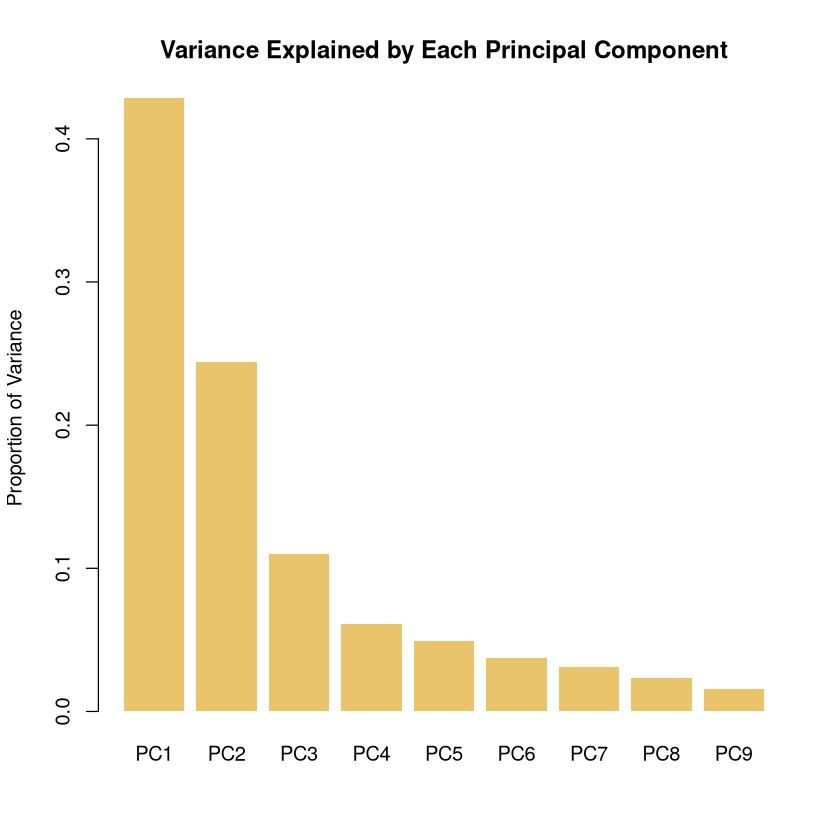

In [61]:
explained_variance <- summary(pca_gbif)$importance[2,]

barplot(explained_variance, main = "Variance Explained by Each Principal Component", 
        col = "#e9c46a", ylab = "Proportion of Variance", border = NA)


### Biplot with loadings

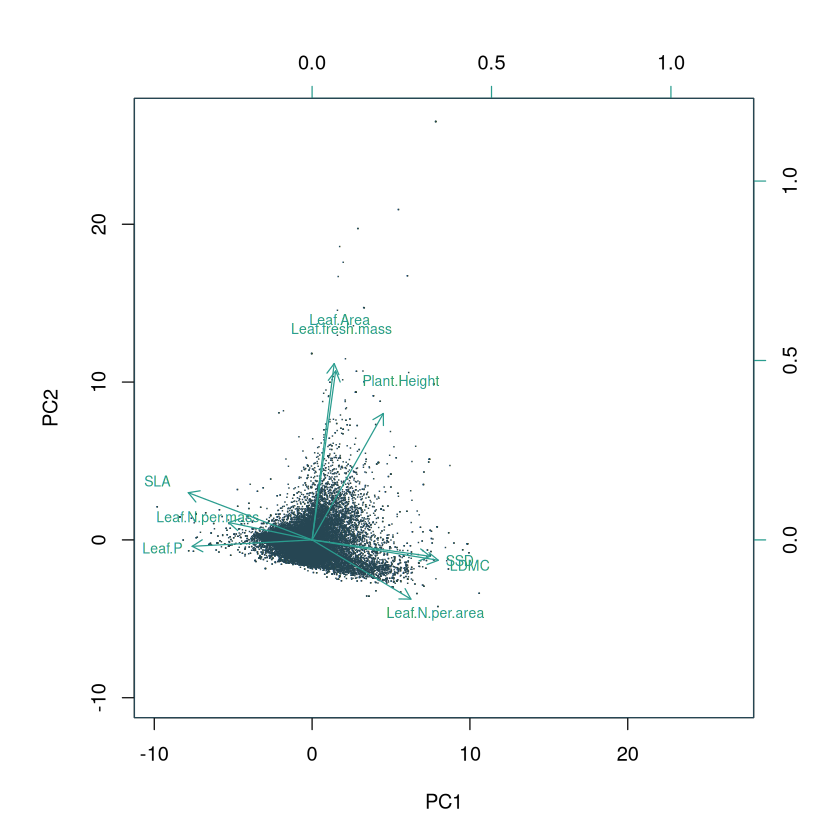

In [68]:
# plot biplot with loadings
biplot(pca_gbif, scale = 0, cex = 0.7, col = c("#264653", "#2a9d8f"), xlabs = rep(".", nrow(pca_gbif$x)))



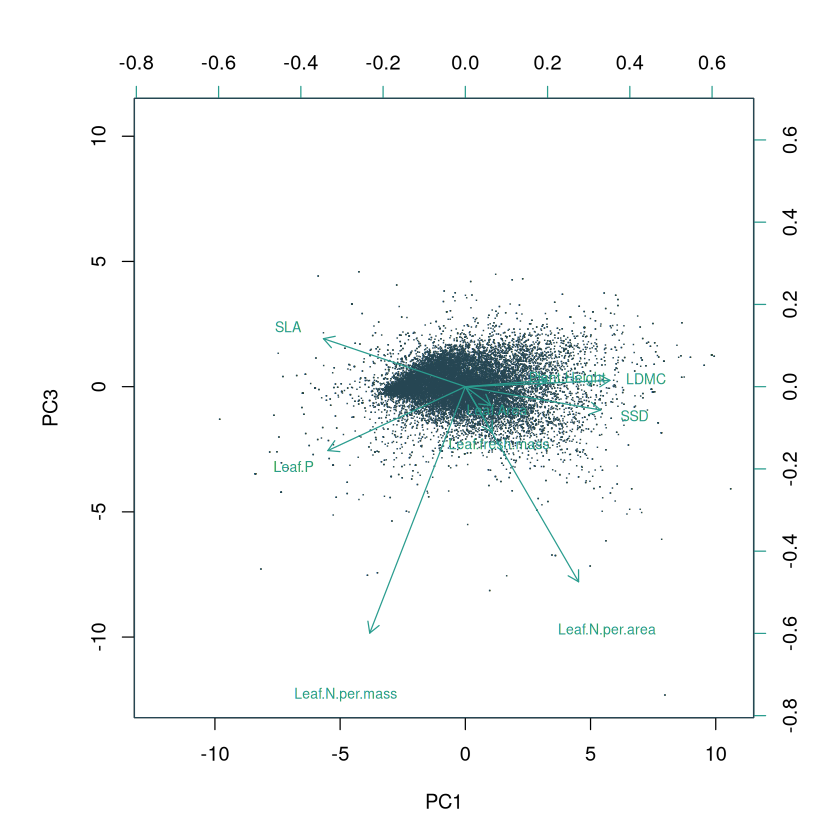

In [69]:
biplot(pca_gbif, choices = c(1, 3), scale = 0, cex = 0.7, col = c("#264653", "#2a9d8f"), xlabs = rep(".", nrow(pca_gbif$x)))


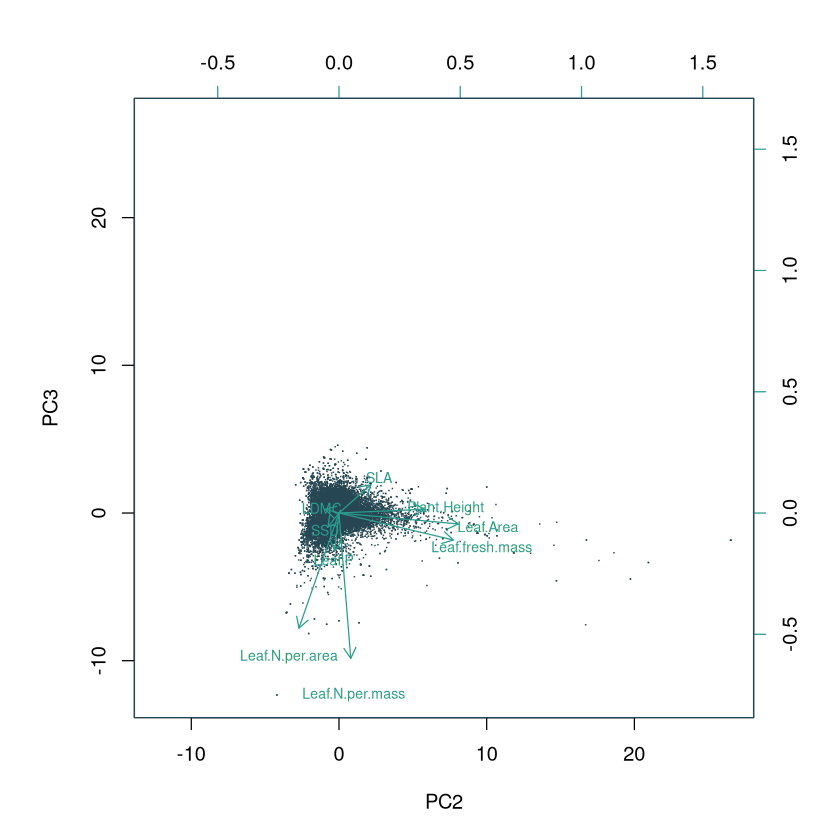

In [70]:
biplot(pca_gbif, choices = c(2, 3), scale = 0, cex = 0.7, col = c("#264653", "#2a9d8f"), xlabs = rep(".", nrow(pca_gbif$x)))


### Global maps

Try to interpret PCs in ecological terms using biplots and global maps

## Optional: Regional shifts

Quantify and visualize shifts in trait space in a biome of interest

| Biome Number | Biome Name |
|---------------|-------------|
| 1  | Tropical & Subtropical Moist Broadleaf Forests |
| 2  | Tropical & Subtropical Dry Broadleaf Forests |
| 3  | Tropical & Subtropical Coniferous Forests |
| 4  | Temperate Broadleaf & Mixed Forests |
| 5  | Temperate Conifer Forests |
| 6  | Boreal Forests / Taiga |
| 7  | Tropical & Subtropical Grasslands, Savannas & Shrublands |
| 8  | Temperate Grasslands, Savannas & Shrublands |
| 9  | Flooded Grasslands & Savannas |
| 10 | Montane Grasslands & Shrublands |
| 11 | Tundra |
| 12 | Mediterranean Forests, Woodlands & Scrub |
| 13 | Deserts & Xeric Shrublands |
| 14 | Mangroves |


In [ ]:
library(h3)
library(dplyr)
library(sf) 

wwf <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos.shp")
print(wwf)

In [ ]:
# Hint: use h3::polyfill(f, res = 3) to get h3 indexes covering a region x, maybe also add buffer

polygon <- wwf[wwf$BIOME == biome_of_interest, ]
region_cells <- h3::polyfill(polygon, res = 3)

filtered_grid_means <- grid_means %>%
    filter(h3_res3 %in% region_cells)